In [2]:
%matplotlib widget
import matplotlib.pyplot as plt
import numpy as np

In [15]:
data = np.load("dataTrue.npy")
print(data.shape)

(6, 1000)


In [80]:
plt.close("all")

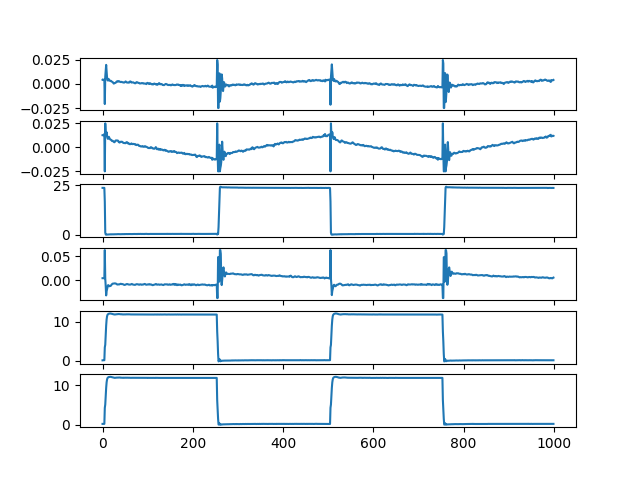

In [81]:
fig, axs = plt.subplots(6,1)

for i in range(6):
    axs[i].plot(data[i])

In [13]:
np.save("dataTrue.npy",data)

In [18]:
fs = 50e6
Vin_dc = 12
Vout_dc = 12/(1-0.5)-0.4
Il_dc = 0.1
Rshunt = 0.1
Rdrv = 1

In [102]:
Vin = Vin_dc+data[0]
Vout = Vout_dc+data[3]
Vdrain = data[2]

Il_ac = (data[0]-data[1])/Rshunt
Il = Il_dc + Il_ac
Vl = data[1]+12-Vdrain
Vd = Vout-Vdrain

Vgate = data[4]
Igate = (data[5]-data[4])/Rdrv

start = np.diff(np.int8(Vgate>5))
print(np.where(start>0))

dutyBase = (np.arange(1000)-6)/500

(array([  6, 506]),)


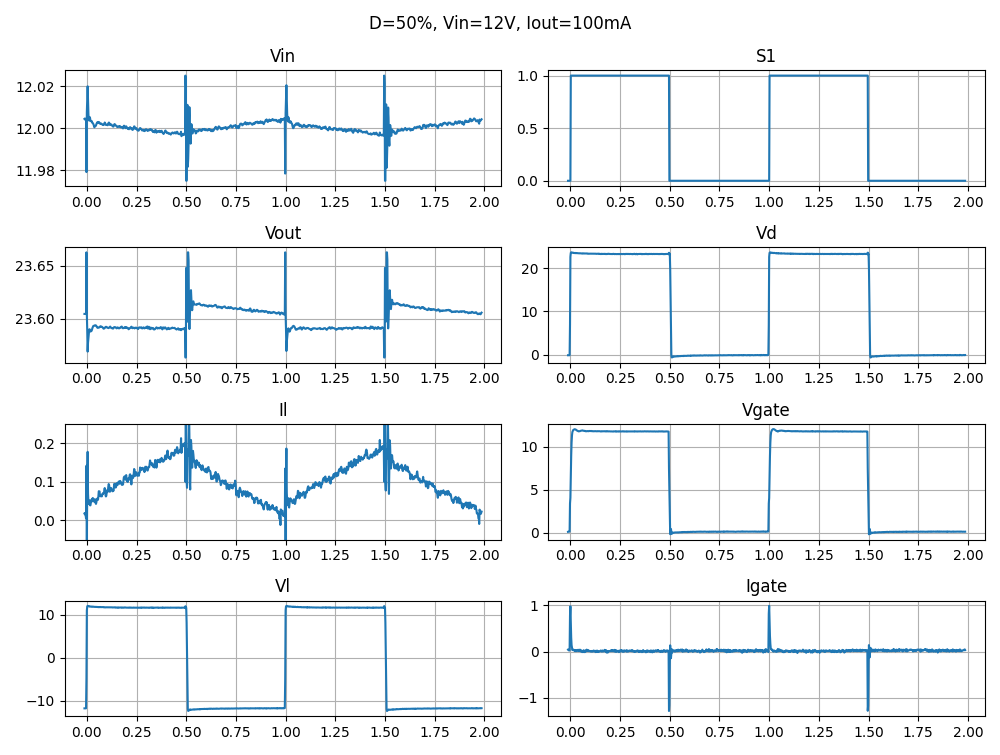

In [103]:
fig2, axs2 = plt.subplots(4,2)
fig2.suptitle("D=50%, Vin=12V, Iout=100mA")
fig2.set_size_inches(10,5*1.51)
axs2[0,0].set_title("Vin")
axs2[0,0].plot(dutyBase,Vin)
axs2[1,0].set_title("Vout")
axs2[1,0].plot(dutyBase,Vout)
axs2[2,0].set_title("Il")
axs2[2,0].plot(dutyBase,Il)
axs2[2,0].set_ylim(-0.05,0.25)

axs2[3,0].set_title("Vl")
axs2[3,0].plot(dutyBase,Vl)
axs2[0,1].set_title("S1")
axs2[0,1].plot(dutyBase,Vgate>5)
axs2[1,1].set_title("Vd")
axs2[1,1].plot(dutyBase,Vd)
axs2[2,1].set_title("Vgate")
axs2[2,1].plot(dutyBase,Vgate)
axs2[3,1].set_title("Igate")
axs2[3,1].plot(dutyBase,Igate)
for i in range(4):
    for j in range(2):
        axs2[i,j].grid("minor")
        # axs2[i,j].set_xlim(-0.01,1.01)
fig2.tight_layout()

501


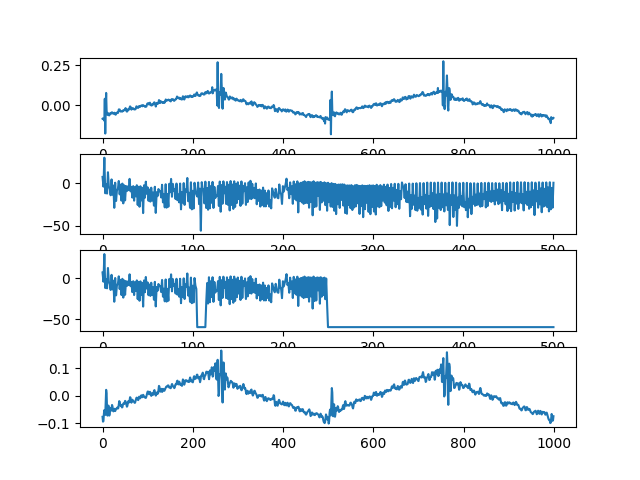

In [59]:
spectreIl = np.fft.rfft(Il-0.1)
nPoints = spectreIl.shape[0]
print(nPoints)
cutoff = 250
spectreRec = np.copy(spectreIl)
spectreRec[cutoff:] = 0
spectreRec[105:115] = 0
base = np.linspace(0,fs/2,nPoints)
figSpec, axss = plt.subplots(4,1)
recon = np.fft.irfft(spectreRec)
axss[0].plot(Il-0.1)
axss[1].plot(20*np.log10(np.abs(spectreIl)))
axss[2].plot(20*np.log10(np.abs(spectreRec)+0.001))
axss[3].plot(recon)

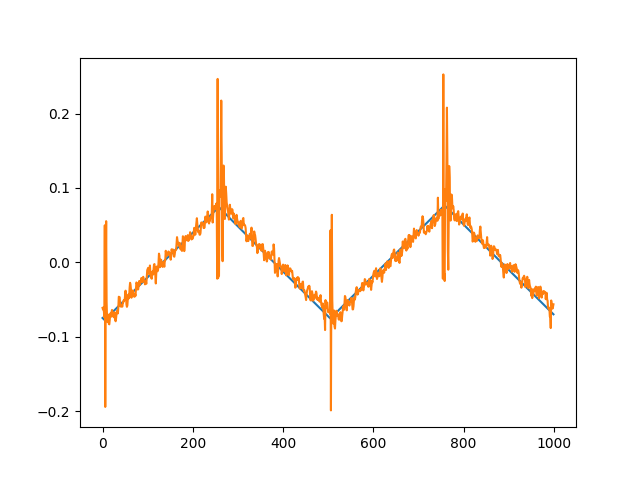

In [120]:
figt = plt.figure("test")
plt.cla()
Vcoil = Vl*600e-9/330e-6
Il_theoretical = np.cumsum(Vl)/fs/390e-6
Il_theoretical = Il_theoretical - np.average(Il_theoretical)
plt.plot(Il_theoretical)
plt.plot(Il_ac-Vcoil)
plt.show()